# Kasus A - Deteksi Penipuan Rekening (Bank Account Fraud)

Objektif: membangun model klasifikasi biner yang menandai pembukaan rekening berpotensi fraud, dengan fokus menangkap sebanyak mungkin fraud pada batas false positive yang dapat ditoleransi bisnis.

Sumber data: `Base.csv` (Bank Account Fraud / BAF dataset, NeurIPS 2022), 1.000.000 baris dan 32 kolom, termasuk label `fraud_bool` dan kolom waktu `month` (0-7).

Metrik: True Positive Rate (recall) pada False Positive Rate <= 5%, ditulis TPR@FPR5%. Accuracy tidak dipakai karena kelas fraud sangat tidak seimbang (sekitar 1,1%); biaya meloloskan fraud jauh lebih besar daripada biaya review manual tambahan. ROC AUC hanya dilaporkan sebagai diagnostik sekunder.

Protokol split: memakai urutan waktu untuk train, tune, dan final test. Bulan 0 dan 1 untuk fit, bulan 2 untuk memilih hyperparameter dan decision threshold, bulan 3 hanya untuk pelaporan metrik akhir satu kali. Bulan test dikeluarkan dari ringkasan EDA, kosakata kategori, fit preprocessing, tuning, pemilihan model, dan penentuan threshold. Notebook hanya memakai bulan 0 sampai 3 sesuai brief.

Catatan sensitif: `customer_age` dan beberapa atribut demografis lain berpotensi sensitif. Proyek ini tidak membuat klaim fairness.

## Mengapa XGBoost

XGBoost menjadi model utama. Pemilihan model hanya memakai bulan 2, sebelum bulan 3 disentuh, dan XGBoost memberi hasil tuning terbaik: TPR 53,42% pada FPR 4,99%, di atas LightGBM (52,42%), CatBoost (53,42% tetapi AUC tie-break lebih rendah), dan Logistic Regression (47,33%). Training berbasis histogram menangani hampir 548.000 baris, enam kolom kategorikal dengan native categorical split, dan nilai hilang, tanpa ekspansi one hot untuk model utama. Tree boosting menangkap efek nonlinear dan interaksi fitur yang tidak dimodelkan langsung oleh baseline Logistic Regression. Pada holdout bulan 3 yang tidak tersentuh, XGBoost juga meraih ROC AUC terbaik (0,9134) dan TPR tertinggi pada threshold beku (68,68%), konsisten dengan pilihan tuning tanpa memengaruhi pilihan tersebut.

XGBoost, LightGBM, dan CatBoost dibandingkan dengan baseline Logistic Regression yang sudah di-tune. Setiap keluarga model melakukan tuning hanya pada bulan 2. Bulan 3 disediakan untuk satu perbandingan akhir dan tidak memilih model yang disimpan. TabPFN berada di luar benchmark ini, jadi hasil tidak mendukung klaim tentang TabPFN atau model lain yang tidak diuji.

Sumber: https://lightgbm.readthedocs.io/en/latest/Features.html, https://lightgbm.readthedocs.io/en/latest/Advanced-Topics.html, https://xgboost.readthedocs.io/en/stable/python/sklearn_estimator.html, dan https://catboost.ai/docs/en/concepts/python-reference_catboostclassifier


## Impor pustaka dan konstanta

Memuat semua pustaka yang dipakai (pandas, scikit-learn, LightGBM, XGBoost, CatBoost, matplotlib), menetapkan seed acak `RANDOM_STATE = 42`, path dataset dan model, serta helper `show_note` untuk menampilkan catatan markdown.


In [46]:
from pathlib import Path
import pickle
import lightgbm as lgb
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
DATA_PATH = Path("data/Base.csv")
MODEL_PATH = Path("model.pkl")

def show_note(text):
    display(Markdown(text))


## Memuat dan memfilter dataset

Memeriksa keberadaan `Base.csv`, memuat dataset, menyaring baris ke bulan 0–3 sesuai brief, dan menyiapkan `eda_df` khusus bulan 0–1 untuk seluruh ringkasan EDA.


In [47]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "Base.csv"
df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "sgpjesus/bank-account-fraud-dataset-neurips-2022",
    file_path,
)

# Previous local-file loader:
# if not DATA_PATH.exists():
#     raise FileNotFoundError(
#         f"Dataset tidak ditemukan di {DATA_PATH.resolve()}. "
#         "Letakkan Base.csv di direktori yang sama dengan notebook ini."
#     )
# df = pd.read_csv(DATA_PATH)

df = df[df["month"].isin([0, 1, 2, 3])].reset_index(drop=True)
eda_df = df[df["month"].isin([0, 1])].copy()

assert set(df["month"].unique()) == {0, 1, 2, 3}, sorted(df["month"].unique())
print(f"Baris setelah filter bulan 0-3: {len(df):,}")
show_note("Bagian berikut memeriksa keseimbangan kelas, nilai hilang, jumlah pengajuan per bulan, dan usia. Ringkasannya hanya memakai bulan pelatihan 0 dan 1.")

Baris setelah filter bulan 0-3: 547,975


Bagian berikut memeriksa keseimbangan kelas, nilai hilang, jumlah pengajuan per bulan, dan usia. Ringkasannya hanya memakai bulan pelatihan 0 dan 1.

## EDA: keseimbangan kelas per bulan

Menghitung jumlah pengajuan, kasus fraud, dan fraud rate pada bulan pelatihan 0–1, ditambah rinciannya per bulan, untuk menunjukkan ketimpangan kelas (fraud sekitar 1%).


In [ ]:
print("Ringkasan eksplorasi hanya memakai bulan pelatihan 0 dan 1.")
print(f"Bentuk data pelatihan: {eda_df.shape}")
fraud_count = int(eda_df["fraud_bool"].sum())
fraud_rate = float(eda_df["fraud_bool"].mean())

overview = pd.DataFrame(
    [
        {"Measure": "Applications", "Value": len(eda_df)},
        {"Measure": "Fraud cases", "Value": fraud_count},
        {"Measure": "Fraud rate", "Value": fraud_rate},
    ]
)
display(overview.style.format({"Value": lambda value: f"{value:,.4f}" if isinstance(value, float) else f"{value:,}"}))

monthly_eda = eda_df.groupby("month").agg(
    Applications=("fraud_bool", "size"),
    Fraud_cases=("fraud_bool", "sum"),
    Fraud_rate=("fraud_bool", "mean"),
)
print("Keseimbangan kelas per bulan")
display(monthly_eda.style.format({"Fraud_rate": "{:.3%}"}))


Ringkasan eksplorasi hanya memakai bulan pelatihan 0 dan 1.
Bentuk data pelatihan: (260060, 32)


,Measure,Value
0,Applications,"260,060.0000"
1,Fraud cases,"2,698.0000"
2,Fraud rate,0.0104


Keseimbangan kelas per bulan


,Applications,Fraud_cases,Fraud_rate
month,,,
0,132440,1500,1.133%
1,127620,1198,0.939%


## EDA: nilai hilang, kardinalitas kategorikal, dan usia

Menampilkan nilai hilang mentah, jumlah kategori unik pada setiap kolom kategorikal, dan ringkasan statistik usia (`customer_age`) menurut label fraud/non-fraud.


In [ ]:
missing_table = eda_df.isna().sum().loc[lambda values: values > 0].rename("Missing rows").to_frame()
print("Nilai hilang mentah")
display(missing_table if not missing_table.empty else pd.DataFrame({"Status": ["Tidak ada nilai hilang mentah"]}))

cat_cols = eda_df.select_dtypes(include=["object", "string"]).columns.tolist()
categorical_summary = pd.Series(
    {col: eda_df[col].nunique() for col in cat_cols},
    name="Observed categories",
).to_frame()
print("Kardinalitas kolom kategorikal")
display(categorical_summary)

age_summary = (
    eda_df.groupby("fraud_bool")["customer_age"]
    .agg(count="size", mean="mean", std="std", min="min", median="median", max="max")
    .rename(index={0: "Non-fraud", 1: "Fraud"})
)
print("Ringkasan usia menurut label")
display(age_summary.style.format({column: "{:.2f}" for column in age_summary.columns if column != "count"}))


Nilai hilang mentah


,Status
0,Tidak ada nilai hilang mentah


Kardinalitas kolom kategorikal


,Observed categories
payment_type,5
employment_status,7
housing_status,7
source,2
device_os,5


Ringkasan usia menurut label


,count,mean,std,min,median,max
fraud_bool,,,,,,
Non-fraud,257362,33.26,12.25,10.00,30.00,90.00
Fraud,2698,40.75,13.46,10.00,40.00,90.00


## Catatan EDA

Menampilkan catatan bahwa fraud hanya sekitar 1% sehingga accuracy dapat menyembunyikan fraud yang terlewat; evaluasi memakai recall pada batas FPR tetap, dan usia berpotensi menjadi atribut sensitif.


In [ ]:
show_note(f"Fraud mencakup {fraud_rate:.2%} dari data pelatihan, sehingga accuracy dapat menyembunyikan fraud yang terlewat. Bandingkan recall pada batas false positive yang tetap. Usia berbeda menurut label dan dapat menjadi atribut sensitif, jadi ini bukan evaluasi fairness.")


Fraud mencakup 1.04% dari data pelatihan, sehingga accuracy dapat menyembunyikan fraud yang terlewat. Bandingkan recall pada batas false positive yang tetap. Usia berbeda menurut label dan dapat menjadi atribut sensitif, jadi ini bukan evaluasi fairness.

## Konversi sentinel -1 menjadi NaN

Mengubah nilai sentinel -1 menjadi NaN hanya pada enam kolom yang tercantum dalam datasheet (nilai negatif sah di kolom lain seperti `intended_balcon_amount` tidak disentuh), lalu menampilkan jumlah nilai hilang per kolom setelah konversi.


In [ ]:
# Datasheet: -1 = missing HANYA untuk enam kolom ini.
# Jangan ubah nilai negatif sah di kolom lain (mis. intended_balcon_amount, velocity_6h).
SENTINEL_COLS = [
    "prev_address_months_count",
    "current_address_months_count",
    "credit_risk_score",
    "bank_months_count",
    "session_length_in_minutes",
    "device_distinct_emails_8w",
]

for col in SENTINEL_COLS:
    assert (eda_df[col] == -1).any(), f"expected -1 sentinel in fit months for {col}"
    df[col] = df[col].mask(df[col] == -1, np.nan)

eda_df = df[df["month"].isin([0, 1])].copy()
sentinel_summary = (
    eda_df[SENTINEL_COLS]
    .isna()
    .sum()
    .rename("Missing rows")
    .to_frame()
)
print("Nilai hilang setelah konversi sentinel")
display(sentinel_summary)
show_note("Grafik berikut hanya merangkum data pelatihan. Nilai sentinel hanya diubah pada enam kolom yang tercantum dalam datasheet.")


Nilai hilang setelah konversi sentinel


,Missing rows
prev_address_months_count,189390
current_address_months_count,953
credit_risk_score,247
bank_months_count,53905
session_length_in_minutes,532
device_distinct_emails_8w,132


Grafik berikut hanya merangkum data pelatihan. Nilai sentinel hanya diubah pada enam kolom yang tercantum dalam datasheet.

## Visualisasi EDA

Menggambar empat grafik: jumlah pengajuan per label, jumlah dan proporsi fraud per bulan, sepuluh fitur dengan nilai hilang terbanyak, dan distribusi usia menurut label.


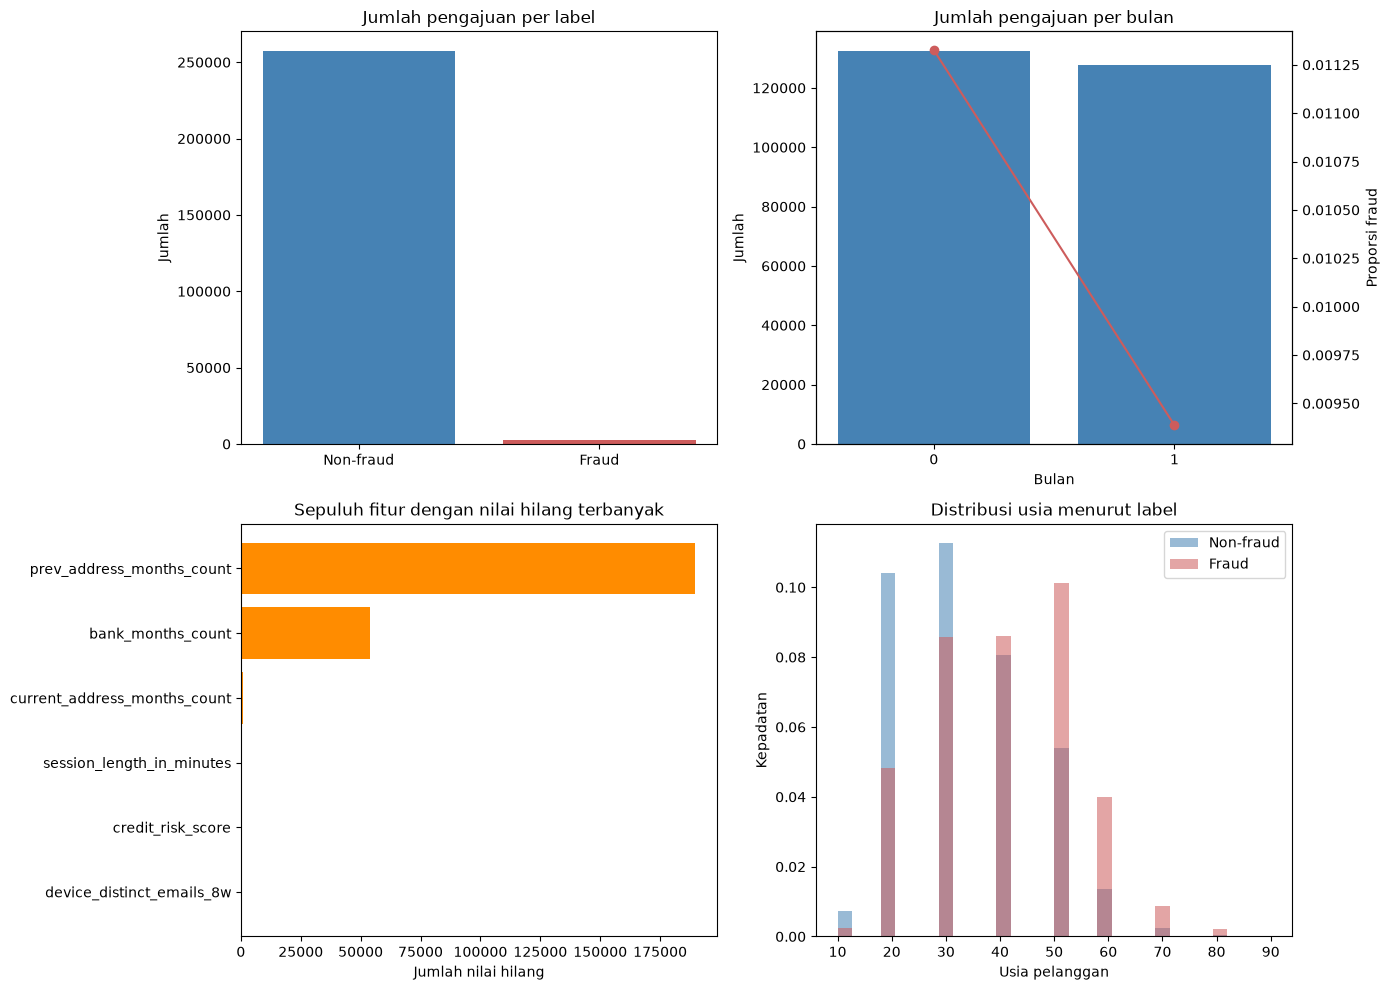

Grafik menunjukkan ketimpangan kelas, variasi antarbulan, nilai hilang dari sentinel, dan distribusi usia. Usia berpotensi sensitif, jadi grafik ini tidak membuktikan fairness.

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

class_counts = eda_df["fraud_bool"].value_counts().reindex([0, 1], fill_value=0)
axes[0, 0].bar(["Non-fraud", "Fraud"], class_counts.values, color=["steelblue", "indianred"])
axes[0, 0].set_title("Jumlah pengajuan per label")
axes[0, 0].set_ylabel("Jumlah")

monthly = eda_df.groupby("month")["fraud_bool"].agg(["size", "mean"])
axes[0, 1].bar(monthly.index.astype(str), monthly["size"], color="steelblue")
axes[0, 1].set_title("Jumlah pengajuan per bulan")
axes[0, 1].set_xlabel("Bulan")
axes[0, 1].set_ylabel("Jumlah")
rate_axis = axes[0, 1].twinx()
rate_axis.plot(monthly.index.astype(str), monthly["mean"], color="indianred", marker="o")
rate_axis.set_ylabel("Proporsi fraud")

missing_counts = eda_df.isna().sum().loc[lambda values: values > 0].sort_values(ascending=False).head(10)
if missing_counts.empty:
    axes[1, 0].text(0.5, 0.5, "Tidak ada nilai hilang", ha="center", va="center")
    axes[1, 0].set_axis_off()
else:
    axes[1, 0].barh(missing_counts.index[::-1], missing_counts.values[::-1], color="darkorange")
    axes[1, 0].set_title("Sepuluh fitur dengan nilai hilang terbanyak")
    axes[1, 0].set_xlabel("Jumlah nilai hilang")

for label, color, name in [(0, "steelblue", "Non-fraud"), (1, "indianred", "Fraud")]:
    age_values = eda_df.loc[eda_df["fraud_bool"] == label, "customer_age"].dropna()
    axes[1, 1].hist(age_values, bins=30, alpha=0.55, color=color, label=name, density=True)
axes[1, 1].set_title("Distribusi usia menurut label")
axes[1, 1].set_xlabel("Usia pelanggan")
axes[1, 1].set_ylabel("Kepadatan")
axes[1, 1].legend()

fig.tight_layout()
plt.show()
plt.close(fig)
show_note("Grafik menunjukkan ketimpangan kelas, variasi antarbulan, nilai hilang dari sentinel, dan distribusi usia. Usia berpotensi sensitif, jadi grafik ini tidak membuktikan fairness.")


## Pembagian data temporal

Menetapkan bulan 0–1 untuk fit, bulan 2 untuk tuning, dan bulan 3 untuk holdout akhir; memisahkan fitur dan target dengan mengeluarkan `month` serta `device_fraud_count` (konstan), lalu menjalankan serangkaian assert untuk menjamin kebersihan split.


In [ ]:
FIT_MONTHS = {0, 1}
TUNE_MONTH = 2
TEST_MONTH = 3

TARGET = "fraud_bool"
EXCLUDED = ["fraud_bool", "month", "device_fraud_count"]
FEATURES = [col for col in df.columns if col not in EXCLUDED]

fit_df = df[df["month"].isin(FIT_MONTHS)].reset_index(drop=True)
tune_df = df[df["month"] == TUNE_MONTH].reset_index(drop=True)
test_df = df[df["month"] == TEST_MONTH].reset_index(drop=True)

X_fit = fit_df[FEATURES]
y_fit = fit_df[TARGET]
X_tune = tune_df[FEATURES]
y_tune = tune_df[TARGET]
X_test = test_df[FEATURES]
y_test = test_df[TARGET]

assert set(fit_df["month"]) == FIT_MONTHS
assert set(tune_df["month"]) == {TUNE_MONTH}
assert set(test_df["month"]) == {TEST_MONTH}
assert set(fit_df["month"]).isdisjoint(tune_df["month"])
assert set(fit_df["month"]).isdisjoint(test_df["month"])
assert set(tune_df["month"]).isdisjoint(test_df["month"])
assert not set(EXCLUDED) & set(FEATURES)
assert y_fit.nunique() == 2 and y_tune.nunique() == 2 and y_test.nunique() == 2
assert len(X_fit) + len(X_tune) + len(X_test) == len(df)
assert df["device_fraud_count"].nunique() == 1


## Ringkasan split

Menampilkan tabel jumlah baris dan fraud rate untuk setiap segmen (fit, tuning, holdout).


In [ ]:
split_summary = pd.DataFrame(
    {
        "Rows": [len(X_fit), len(X_tune), len(X_test)],
        "Fraud rate": [y_fit.mean(), y_tune.mean(), y_test.mean()],
    },
    index=["Fit months 0 and 1", "Tuning month 2", "Final holdout month 3"],
)
display(split_summary.style.format({"Rows": "{:,}", "Fraud rate": "{:.3%}"}))
show_note("Model dilatih pada bulan 0 dan 1. Bulan 2 dipakai memilih parameter dan threshold. Bulan 3 tidak disentuh sampai evaluasi akhir.")


,Rows,Fraud rate
Fit months 0 and 1,"260,060",1.037%
Tuning month 2,"136,979",0.875%
Final holdout month 3,"150,936",0.922%


Model dilatih pada bulan 0 dan 1. Bulan 2 dipakai memilih parameter dan threshold. Bulan 3 tidak disentuh sampai evaluasi akhir.

## Pemodelan dan perbandingan

Empat keluarga model dibandingkan. Logistic Regression menjadi baseline linear. LightGBM, XGBoost, dan CatBoost menguji tree boosting dengan native handling untuk data terstruktur. Setiap keluarga memiliki dua kandidat parameter. Pelatihan memakai bulan 0 dan 1. Bulan 2 memilih parameter dan decision threshold berdasarkan TPR dengan FPR paling tinggi lima persen.

Aturan holdout: bulan 3 hanya dipakai untuk evaluasi akhir. Bulan ini tidak digunakan untuk melatih preprocessing, menentukan kategori, memilih parameter, menentukan threshold, atau memilih model. FPR dapat melampaui lima persen jika pola fraud berubah dari waktu ke waktu.


## Definisi metrik TPR@FPR5% dan pencatat kandidat

Memisahkan kolom numerik dan kategorikal, mendefinisikan fungsi `tpr_at_fpr_limit` (TPR maksimum pada FPR ≤ 5%, lengkap dengan validasi input), serta `record_candidate` untuk menyimpan hasil tuning setiap kandidat model.


In [ ]:
from sklearn.metrics import roc_auc_score

CAT_COLS = X_fit.select_dtypes(include=["object", "string"]).columns.tolist()
if "email_is_free" not in CAT_COLS:
    CAT_COLS.append("email_is_free")
NUM_COLS = [col for col in FEATURES if col not in CAT_COLS]

assert set(CAT_COLS) | set(NUM_COLS) == set(FEATURES)
assert not set(CAT_COLS) & set(NUM_COLS)

def tpr_at_fpr_limit(y_true, y_score, limit=0.05):
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score, dtype=float)
    if y_true.ndim != 1 or y_score.ndim != 1 or len(y_true) != len(y_score):
        raise ValueError("labels and scores must be one dimensional vectors of equal length")
    if len(y_true) == 0 or not np.isin(y_true, [0, 1]).all():
        raise ValueError("labels must be a nonempty binary vector")
    if np.unique(y_true).size != 2 or not np.isfinite(y_score).all():
        raise ValueError("labels must contain both classes and scores must be finite")
    if not 0 <= limit <= 1:
        raise ValueError("limit must be between zero and one")
    fpr, tpr, thresholds = roc_curve(y_true, y_score)
    index = np.flatnonzero(fpr <= limit)[-1]
    return float(tpr[index]), float(fpr[index]), float(thresholds[index])

candidate_records = []

def record_candidate(model_name, params, estimator, probabilities):
    tune_tpr, tune_fpr, tune_threshold = tpr_at_fpr_limit(y_tune, probabilities)
    candidate_records.append(
        {
            "Model": model_name,
            "Parameters": params,
            "Tuning TPR": tune_tpr,
            "Tuning FPR": tune_fpr,
            "Tuning threshold": tune_threshold,
            "Tuning ROC AUC": roc_auc_score(y_tune, probabilities),
            "Estimator": estimator,
        }
    )


## Pipeline Logistic Regression

Membangun pipeline baseline linear: imputasi median + standard scaling untuk fitur numerik, imputasi modus + one-hot encoding untuk fitur kategorikal, diikuti LogisticRegression dengan class weight balanced.


In [ ]:
def make_logistic(C):
    return Pipeline(
        [
            (
                "prep",
                ColumnTransformer(
                    [
                        (
                            "num",
                            Pipeline(
                                [
                                    ("impute", SimpleImputer(strategy="median")),
                                    ("scale", StandardScaler()),
                                ]
                            ),
                            NUM_COLS,
                        ),
                        (
                            "cat",
                            Pipeline(
                                [
                                    ("impute", SimpleImputer(strategy="most_frequent")),
                                    ("onehot", OneHotEncoder(handle_unknown="ignore")),
                                ]
                            ),
                            CAT_COLS,
                        ),
                    ]
                ),
            ),
            (
                "model",
                LogisticRegression(
                    C=C,
                    class_weight="balanced",
                    max_iter=1000,
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    )


## Tuning Logistic Regression

Melatih dua kandidat (C = 0.1 dan C = 1.0) pada bulan 0–1, menilainya di bulan 2, dan menampilkan tabel hasil tuning baseline linear.


In [ ]:
for C in [0.1, 1.0]:
    estimator = make_logistic(C)
    estimator.fit(X_fit, y_fit)
    record_candidate(
        "Logistic Regression",
        {"C": C, "class_weight": "balanced"},
        estimator,
        estimator.predict_proba(X_tune)[:, 1],
    )

print(f"Fitur numerik: {len(NUM_COLS)}")
print(f"Fitur kategorikal: {len(CAT_COLS)}")
print("Jumlah kandidat Logistic Regression:", sum(row["Model"] == "Logistic Regression" for row in candidate_records))

lr_tuning_table = pd.DataFrame(
    [
        {
            "C": row["Parameters"]["C"],
            "Tuning TPR": row["Tuning TPR"],
            "Tuning FPR": row["Tuning FPR"],
            "Tuning ROC AUC": row["Tuning ROC AUC"],
        }
        for row in candidate_records
        if row["Model"] == "Logistic Regression"
    ]
)
display(lr_tuning_table.style.format({
    "C": "{:.1f}",
    "Tuning TPR": "{:.3%}",
    "Tuning FPR": "{:.3%}",
    "Tuning ROC AUC": "{:.4f}",
}))
best_lr = best_candidate = max(
    [row for row in candidate_records if row["Model"] == "Logistic Regression"],
    key=lambda row: (row["Tuning TPR"], row["Tuning ROC AUC"]),
)
show_note(f"Logistic Regression menjadi pembanding linear. TPR terbaik pada bulan 2 adalah {best_lr['Tuning TPR']:.2%} dengan FPR {best_lr['Tuning FPR']:.2%}. Bagian berikut membandingkan LightGBM dan XGBoost memakai kategori yang berasal dari data pelatihan saja.")


Fitur numerik: 23
Fitur kategorikal: 6
Jumlah kandidat Logistic Regression: 2


,C,Tuning TPR,Tuning FPR,Tuning ROC AUC
0,0.1,47.329%,4.967%,0.8657
1,1.0,47.329%,4.971%,0.8657


Logistic Regression menjadi pembanding linear. TPR terbaik pada bulan 2 adalah 47.33% dengan FPR 4.97%. Bagian berikut membandingkan LightGBM dan XGBoost memakai kategori yang berasal dari data pelatihan saja.

## Persiapan kategorikal untuk model tree

Mengubah kolom kategorikal menjadi pandas categorical dtype memakai kosakata kategori dari bulan pelatihan saja, sehingga kategori baru pada bulan berikutnya diperlakukan sebagai nilai hilang. Juga menghitung `scale_pos_weight` untuk mengatasi ketimpangan kelas.


In [ ]:
TREE_CAT_COLS = CAT_COLS
X_fit_tree = X_fit.copy()
X_tune_tree = X_tune.copy()
X_test_tree = X_test.copy()

for col in TREE_CAT_COLS:
    fit_categories = pd.Index(X_fit[col].dropna().unique()).sort_values()
    category_dtype = pd.CategoricalDtype(categories=fit_categories)
    X_fit_tree[col] = X_fit_tree[col].astype(category_dtype)
    X_tune_tree[col] = X_tune_tree[col].astype(category_dtype)
    X_test_tree[col] = X_test_tree[col].astype(category_dtype)

assert X_fit_tree.columns.tolist() == X_tune_tree.columns.tolist() == X_test_tree.columns.tolist()
assert X_fit_tree[TREE_CAT_COLS].isna().sum().sum() == 0
assert set(FIT_MONTHS).isdisjoint({TUNE_MONTH, TEST_MONTH})

n_negative = int((y_fit == 0).sum())
n_positive = int((y_fit == 1).sum())
imbalance_weight = n_negative / n_positive


## Tuning LightGBM

Melatih dua kandidat LightGBM dengan native categorical handling dan class weighting pada bulan 0–1, lalu merekam hasil evaluasinya di bulan 2.


In [ ]:
lgbm_candidates = [
    {"n_estimators": 250, "learning_rate": 0.05, "num_leaves": 15},
    {"n_estimators": 400, "learning_rate": 0.03, "num_leaves": 31},
]
for params in lgbm_candidates:
    estimator = lgb.LGBMClassifier(
        objective="binary",
        scale_pos_weight=imbalance_weight,
        random_state=RANDOM_STATE,
        n_jobs=4,
        verbosity=-1,
        **params,
    )
    estimator.fit(X_fit_tree, y_fit, categorical_feature=TREE_CAT_COLS)
    record_candidate(
        "LightGBM",
        params,
        estimator,
        estimator.predict_proba(X_tune_tree)[:, 1],
    )


## Tuning XGBoost

Melatih dua kandidat XGBoost (hist tree, native categorical) pada bulan 0–1 dan merekam hasil evaluasinya di bulan 2.


In [ ]:
xgb_candidates = [
    {"n_estimators": 250, "learning_rate": 0.05, "max_depth": 4},
    {"n_estimators": 350, "learning_rate": 0.05, "max_depth": 6},
]
for params in xgb_candidates:
    estimator = XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        enable_categorical=True,
        scale_pos_weight=imbalance_weight,
        subsample=0.85,
        colsample_bytree=0.85,
        random_state=RANDOM_STATE,
        n_jobs=4,
        verbosity=0,
        **params,
    )
    estimator.fit(X_fit_tree, y_fit)
    record_candidate(
        "XGBoost",
        params,
        estimator,
        estimator.predict_proba(X_tune_tree)[:, 1],
    )

print("Tuning LightGBM dan XGBoost selesai pada bulan 2 memakai kategori dari data pelatihan saja.")
show_note("LightGBM dan XGBoost masing-masing menguji dua konfigurasi pohon. Kategori baru pada bulan berikutnya diperlakukan sebagai nilai hilang karena kosakata kategori hanya berasal dari periode pelatihan.")


Tuning LightGBM dan XGBoost selesai pada bulan 2 memakai kategori dari data pelatihan saja.


LightGBM dan XGBoost masing-masing menguji dua konfigurasi pohon. Kategori baru pada bulan berikutnya diperlakukan sebagai nilai hilang karena kosakata kategori hanya berasal dari periode pelatihan.

## Tuning CatBoost

Menyiapkan frame dengan mengganti NaN kategorikal menjadi penanda `__missing__`, lalu melatih dua kandidat CatBoost dengan auto class weighting dan merekam hasil evaluasinya di bulan 2.


In [ ]:
def prepare_catboost_frame(frame):
    prepared = frame.copy()
    for col in CAT_COLS:
        prepared[col] = prepared[col].astype("string").fillna("__missing__").astype(str)
    return prepared

X_fit_cat = prepare_catboost_frame(X_fit)
X_tune_cat = prepare_catboost_frame(X_tune)
X_test_cat = prepare_catboost_frame(X_test)

catboost_candidates = [
    {"iterations": 250, "depth": 6, "learning_rate": 0.05},
    {"iterations": 350, "depth": 8, "learning_rate": 0.03},
]
for params in catboost_candidates:
    estimator = CatBoostClassifier(
        loss_function="Logloss",
        auto_class_weights="Balanced",
        cat_features=CAT_COLS,
        random_seed=RANDOM_STATE,
        thread_count=4,
        verbose=False,
        allow_writing_files=False,
        **params,
    )
    estimator.fit(X_fit_cat, y_fit)
    record_candidate(
        "CatBoost",
        params,
        estimator,
        estimator.predict_proba(X_tune_cat)[:, 1],
    )


## Perbandingan hasil tuning

Menampilkan tabel seluruh kandidat pada bulan 2, memilih kandidat terbaik per keluarga model (TPR tertinggi, tie-break ROC AUC), dan menandai pemenang keseluruhan — semuanya hanya memakai bulan 2.


In [ ]:
candidate_tuning_table = pd.DataFrame(
    [
        {
            "Model": row["Model"],
            "Parameters": row["Parameters"],
            "Tuning TPR": row["Tuning TPR"],
            "Tuning FPR": row["Tuning FPR"],
            "Tuning threshold": row["Tuning threshold"],
            "Tuning ROC AUC": row["Tuning ROC AUC"],
        }
        for row in candidate_records
    ]
)
print("Hasil tuning temporal pada bulan 2")
candidate_tuning_table["Parameters"] = candidate_tuning_table["Parameters"].map(str)
display(
    candidate_tuning_table.style.format(
        {
            "Tuning TPR": "{:.3%}",
            "Tuning FPR": "{:.3%}",
            "Tuning threshold": "{:.6f}",
            "Tuning ROC AUC": "{:.4f}",
        }
    )
)

best_candidates = {}
for model_name in ["Logistic Regression", "LightGBM", "XGBoost", "CatBoost"]:
    candidates = [row for row in candidate_records if row["Model"] == model_name]
    best_candidates[model_name] = max(
        candidates,
        key=lambda row: (row["Tuning TPR"], row["Tuning ROC AUC"]),
    )

print("Satu kandidat per keluarga model dipilih hanya dengan bulan 2.")
best_overall_tuning = max(
    best_candidates.values(),
    key=lambda row: (row["Tuning TPR"], row["Tuning ROC AUC"]),
)
show_note(f"{best_overall_tuning['Model']} memperoleh skor seleksi terbaik pada bulan 2, dengan TPR {best_overall_tuning['Tuning TPR']:.2%} dan FPR {best_overall_tuning['Tuning FPR']:.2%}. Ini hasil tuning, bukan hasil uji akhir.")


Hasil tuning temporal pada bulan 2


,Model,Parameters,Tuning TPR,Tuning FPR,Tuning threshold,Tuning ROC AUC
0,Logistic Regression,"{'C': 0.1, 'class_weight': 'balanced'}",47.329%,4.967%,0.785586,0.8657
1,Logistic Regression,"{'C': 1.0, 'class_weight': 'balanced'}",47.329%,4.971%,0.785624,0.8657
2,LightGBM,"{'n_estimators': 250, 'learning_rate': 0.05, 'num_leaves': 15}",51.002%,4.999%,0.764404,0.8782
3,LightGBM,"{'n_estimators': 400, 'learning_rate': 0.03, 'num_leaves': 31}",52.421%,4.942%,0.709474,0.8803
4,XGBoost,"{'n_estimators': 250, 'learning_rate': 0.05, 'max_depth': 4}",53.422%,4.992%,0.730153,0.8866
5,XGBoost,"{'n_estimators': 350, 'learning_rate': 0.05, 'max_depth': 6}",49.249%,4.999%,0.631534,0.8697
6,CatBoost,"{'iterations': 250, 'depth': 6, 'learning_rate': 0.05}",53.422%,4.981%,0.722039,0.8837
7,CatBoost,"{'iterations': 350, 'depth': 8, 'learning_rate': 0.03}",51.836%,4.955%,0.683616,0.8760


Satu kandidat per keluarga model dipilih hanya dengan bulan 2.


XGBoost memperoleh skor seleksi terbaik pada bulan 2, dengan TPR 53.42% dan FPR 4.99%. Ini hasil tuning, bukan hasil uji akhir.

## Pemeriksaan mandiri metrik

Menguji `tpr_at_fpr_limit` dengan kasus sintetis (ranking sempurna dan beberapa input tidak valid) untuk memastikan fungsi metrik benar sebelum dipakai pada data uji.


In [ ]:
# Pemeriksaan mandiri sintetis: ranking sempurna memberi TPR=1 pada FPR=0.
_test = tpr_at_fpr_limit([0, 0, 1, 1], [0.1, 0.2, 0.8, 0.9])
assert _test[0] == 1.0 and _test[1] == 0.0, _test
for _bad in (
    lambda: tpr_at_fpr_limit([0, 0], [0.2, 0.3]),
    lambda: tpr_at_fpr_limit([0, 1], [0.2, np.nan]),
    lambda: tpr_at_fpr_limit([0, 1], [0.2, 0.3], limit=1.1),
):
    try:
        _bad()
    except ValueError:
        pass
    else:
        raise AssertionError("invalid metric input was accepted")

print("Pemeriksaan mandiri TPR@FPR5% berhasil")
show_note("Pemeriksaan mandiri berhasil. Bagian berikut menerapkan threshold dari bulan 2 ke bulan 3 satu kali, tanpa kalibrasi ulang.")


Pemeriksaan mandiri TPR@FPR5% berhasil


Pemeriksaan mandiri berhasil. Bagian berikut menerapkan threshold dari bulan 2 ke bulan 3 satu kali, tanpa kalibrasi ulang.

## Evaluasi holdout bulan 3

Menghitung probabilitas bulan 3 untuk setiap model terbaik dengan format input yang sesuai per pustaka, menerapkan threshold beku dari bulan 2, dan menghitung confusion matrix, TPR, FPR, precision, ROC AUC, serta TPR@FPR5%.


In [ ]:
test_input_by_model = {
    "Logistic Regression": X_test,
    "LightGBM": X_test_tree,
    "XGBoost": X_test_tree,
    "CatBoost": X_test_cat,
}

test_probabilities = {}
test_metric_rows = []
for model_name, selected in best_candidates.items():
    scores = selected["Estimator"].predict_proba(test_input_by_model[model_name])[:, 1]
    test_probabilities[model_name] = scores
    threshold = selected["Tuning threshold"]
    predicted_fraud = scores >= threshold
    true_positive = int(((y_test == 1) & predicted_fraud).sum())
    false_positive = int(((y_test == 0) & predicted_fraud).sum())
    true_negative = int(((y_test == 0) & ~predicted_fraud).sum())
    false_negative = int(((y_test == 1) & ~predicted_fraud).sum())
    test_metric_rows.append(
        {
            "Model": model_name,
            "ROC AUC": roc_auc_score(y_test, scores),
            "TPR on month 3": true_positive / int((y_test == 1).sum()),
            "FPR on month 3": false_positive / int((y_test == 0).sum()),
            "Precision": true_positive / max(true_positive + false_positive, 1),
            "TPR@FPR5% on month 3": tpr_at_fpr_limit(y_test, scores)[0],
            "Threshold from month 2": threshold,
            "True positives": true_positive,
            "False positives": false_positive,
            "True negatives": true_negative,
            "False negatives": false_negative,
            "Flagged applications": true_positive + false_positive,
        }
    )

test_metric_summary = pd.DataFrame(test_metric_rows)


## Tabel metrik holdout

Menampilkan tabel metrik akhir dan jumlah keputusan (TP/FP/TN/FN) pada threshold beku, dengan catatan bahwa FPR bulan 3 boleh melampaui 5% karena drift temporal.


In [ ]:
print("Metrik holdout akhir dengan threshold dari bulan 2")
metric_columns = [
    "Model",
    "ROC AUC",
    "TPR on month 3",
    "TPR@FPR5% on month 3",
    "FPR on month 3",
    "Precision",
    "Threshold from month 2",
]
display(
    test_metric_summary[metric_columns].style.format(
        {
            "ROC AUC": "{:.4f}",
            "TPR on month 3": "{:.2%}",
            "TPR@FPR5% on month 3": "{:.2%}",
            "FPR on month 3": "{:.2%}",
            "Precision": "{:.2%}",
            "Threshold from month 2": "{:.6f}",
        }
    )
)

print("Jumlah keputusan pada threshold beku")
decision_columns = [
    "Model",
    "True positives",
    "False positives",
    "True negatives",
    "False negatives",
    "Flagged applications",
]
display(test_metric_summary[decision_columns].style.format("{:,}", subset=decision_columns[1:]))
print("FPR bulan 3 dapat melampaui lima persen karena drift temporal. Threshold test tidak diubah.")


Metrik holdout akhir dengan threshold dari bulan 2


,Model,ROC AUC,TPR on month 3,TPR@FPR5% on month 3,FPR on month 3,Precision,Threshold from month 2
0,Logistic Regression,0.8898,62.50%,51.15%,8.08%,6.72%,0.785586
1,LightGBM,0.9078,67.24%,55.46%,8.79%,6.65%,0.709474
2,XGBoost,0.9134,68.68%,57.83%,8.76%,6.80%,0.730153
3,CatBoost,0.9120,68.53%,57.18%,8.65%,6.87%,0.722039


Jumlah keputusan pada threshold beku


,Model,True positives,False positives,True negatives,False negatives,Flagged applications
0,Logistic Regression,870,"12,085","137,459",522,"12,955"
1,LightGBM,936,"13,148","136,396",456,"14,084"
2,XGBoost,956,"13,101","136,443",436,"14,057"
3,CatBoost,954,"12,942","136,602",438,"13,896"


FPR bulan 3 dapat melampaui lima persen karena drift temporal. Threshold test tidak diubah.


## Visualisasi perbandingan dan confusion matrix

Menggambar bar chart perbandingan metrik antar model dan heatmap confusion matrix model final (XGBoost) pada bulan 3.


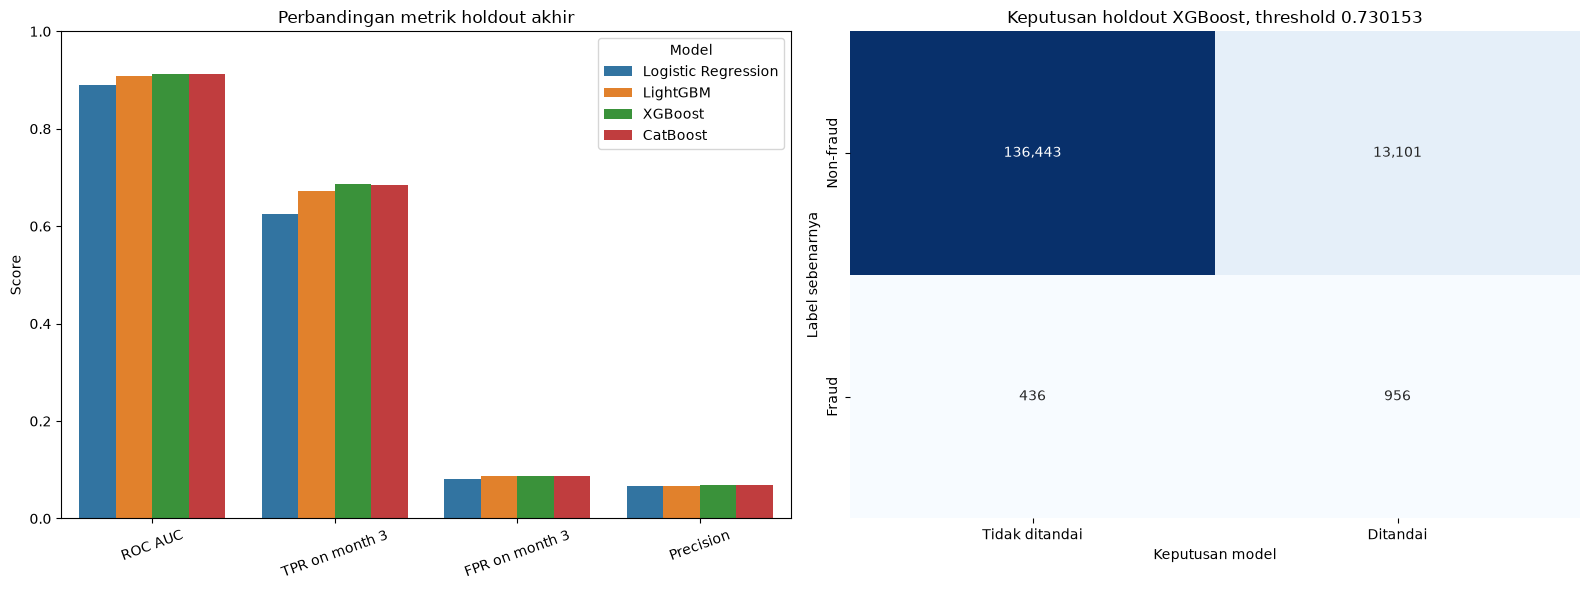

In [ ]:
test_metric_plot = test_metric_summary.melt(
    id_vars="Model",
    value_vars=["ROC AUC", "TPR on month 3", "FPR on month 3", "Precision"],
    var_name="Metric",
    value_name="Score",
)
FINAL_MODEL_NAME = "XGBoost"
final_test_row = test_metric_summary.loc[
    test_metric_summary["Model"] == FINAL_MODEL_NAME
].iloc[0]
final_confusion = np.array(
    [
        [final_test_row["True negatives"], final_test_row["False positives"]],
        [final_test_row["False negatives"], final_test_row["True positives"]],
    ],
    dtype=int,
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(
    data=test_metric_plot,
    x="Metric",
    y="Score",
    hue="Model",
    errorbar=None,
    ax=axes[0],
)
axes[0].set_title("Perbandingan metrik holdout akhir")
axes[0].set_xlabel("")
axes[0].set_ylabel("Score")
axes[0].tick_params(axis="x", rotation=20)
axes[0].set_ylim(0, 1)
axes[0].legend(title="Model")

sns.heatmap(
    final_confusion,
    annot=True,
    fmt=",",
    cmap="Blues",
    cbar=False,
    xticklabels=["Tidak ditandai", "Ditandai"],
    yticklabels=["Non-fraud", "Fraud"],
    ax=axes[1],
)
axes[1].set_title(
    f"Keputusan holdout {FINAL_MODEL_NAME}, threshold {final_test_row['Threshold from month 2']:.6f}"
)
axes[1].set_xlabel("Keputusan model")
axes[1].set_ylabel("Label sebenarnya")
fig.tight_layout()
plt.show()
plt.close(fig)


## Kurva ROC holdout

Menggambar kurva ROC keempat model pada bulan 3 beserta titik operasi threshold beku dan garis referensi FPR 5%.


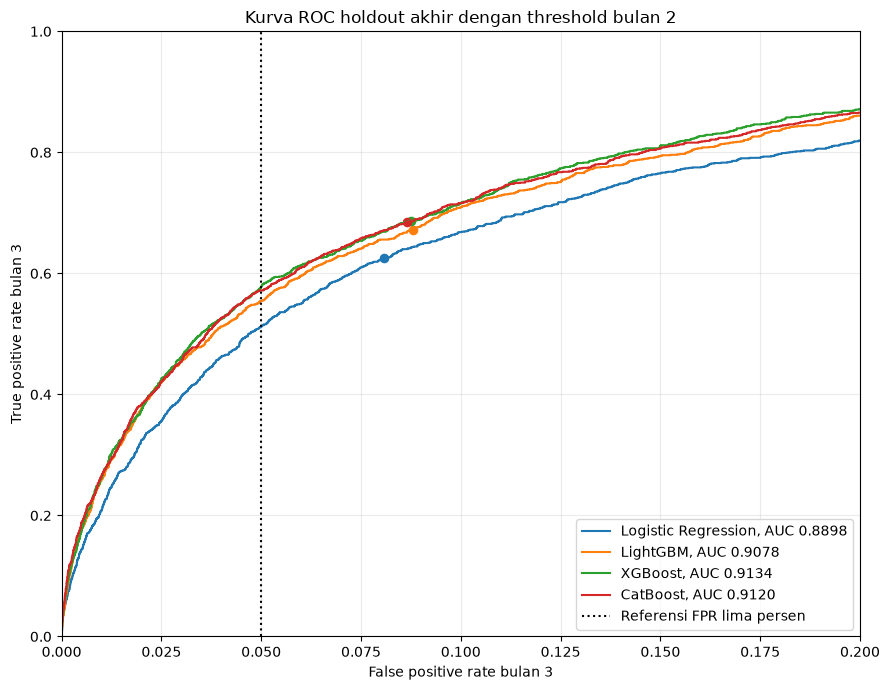

In [ ]:
fig, ax = plt.subplots(figsize=(9, 7))
for model_name, scores in test_probabilities.items():
    test_fpr_curve, test_tpr_curve, _ = roc_curve(y_test, scores)
    ax.plot(
        test_fpr_curve,
        test_tpr_curve,
        label=f"{model_name}, AUC {roc_auc_score(y_test, scores):.4f}",
    )
    fixed_threshold = best_candidates[model_name]["Tuning threshold"]
    test_decision = scores >= fixed_threshold
    point_fpr = float(((y_test == 0) & test_decision).sum() / (y_test == 0).sum())
    point_tpr = float(((y_test == 1) & test_decision).sum() / (y_test == 1).sum())
    ax.scatter([point_fpr], [point_tpr], s=35)
ax.axvline(0.05, color="black", linestyle=":", label="Referensi FPR lima persen")
ax.set_xlim(0, 0.2)
ax.set_ylim(0, 1)
ax.set_xlabel("False positive rate bulan 3")
ax.set_ylabel("True positive rate bulan 3")
ax.set_title("Kurva ROC holdout akhir dengan threshold bulan 2")
ax.legend(loc="lower right")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()
plt.close(fig)


## Penyimpanan dan verifikasi model

Menyimpan model final (XGBoost) beserta threshold beku ke `model.pkl`, memuat ulang untuk memverifikasi prediksi identik, dan menampilkan ringkasan akhir hasil.


In [ ]:
final_model = best_candidates[FINAL_MODEL_NAME]["Estimator"]
# XGBoost tidak punya atribut decision_threshold_, jadi threshold bulan 2
# yang dibekukan disimpan sebagai atribut biasa pada estimator.
final_model.decision_threshold_ = float(best_candidates[FINAL_MODEL_NAME]["Tuning threshold"])
final_test_scores = test_probabilities[FINAL_MODEL_NAME]
with MODEL_PATH.open("wb") as model_file:
    pickle.dump(final_model, model_file)
with MODEL_PATH.open("rb") as model_file:
    final_model_reloaded = pickle.load(model_file)

reloaded_scores = final_model_reloaded.predict_proba(X_test_tree.iloc[:100])[:, 1]
np.testing.assert_array_equal(reloaded_scores, final_test_scores[:100])
assert final_model_reloaded.decision_threshold_ == best_candidates[FINAL_MODEL_NAME]["Tuning threshold"]

size_bytes = MODEL_PATH.stat().st_size
assert size_bytes > 0
print(f"Model {FINAL_MODEL_NAME} hasil tuning disimpan: {MODEL_PATH.resolve()} ({size_bytes:,} byte)")
print("Prediksi holdout dari model yang dimuat ulang cocok untuk 100 baris pertama.")

highest_auc = test_metric_summary.loc[test_metric_summary["ROC AUC"].idxmax()]
highest_tpr = test_metric_summary.loc[test_metric_summary["TPR on month 3"].idxmax()]
all_test_fprs_over_limit = bool((test_metric_summary["FPR on month 3"] > 0.05).all())
show_note(f"{highest_auc['Model']} memiliki ROC AUC tertinggi pada bulan 3, yaitu {highest_auc['ROC AUC']:.4f}. {highest_tpr['Model']} memiliki TPR tertinggi pada threshold beku, yaitu {highest_tpr['TPR on month 3']:.2%}. Semua model melampaui target FPR lima persen pada bulan 3: {all_test_fprs_over_limit}. Ini menunjukkan drift temporal. Threshold bulan 3 tidak diubah. Hasil ini bukan evaluasi fairness.")


Model XGBoost hasil tuning disimpan: D:\Cakrawala\SMT 5\MLOPs\Bank Fraud Prediction Model\model.pkl (446,326 byte)
Prediksi holdout dari model yang dimuat ulang cocok untuk 100 baris pertama.


XGBoost memiliki ROC AUC tertinggi pada bulan 3, yaitu 0.9134. XGBoost memiliki TPR tertinggi pada threshold beku, yaitu 68.68%. Semua model melampaui target FPR lima persen pada bulan 3: True. Ini menunjukkan drift temporal. Threshold bulan 3 tidak diubah. Hasil ini bukan evaluasi fairness.